### Business Problem

The rapid explosion of AI models on platforms like Hugging Face makes it difficult for developers, businesses, and researchers to find the right tool for their needs. Because these models vary greatly in their capabilities, programming frameworks, languages, and legal licenses—and there is no single master list to compare them—finding the right one requires tedious manual searching. This lack of clear, centralized information leads to wasted development time, makes it hard to compare model popularity and support, and risks organizations accidentally using models with restrictive legal terms. Ultimately, without an easy way to evaluate and compare AI models, choosing the right technology remains slow, inefficient, and risky.

### Problem Statement

The AI ecosystem is expanding rapidly, with thousands of new models being released across different domains. However, the available information is scattered across web pages and lacks a structured format for analysis. This makes it difficult to compare models based on their capabilities, popularity, framework, licensing, language support, and community engagement. Therefore, there is a need for an automated system that can collect, organize, and analyze AI model metadata to support efficient model discovery and informed decision-making.

### Objective

+ Automate AI model data collection using Selenium. 
+ Create a structured dataset from Hugging Face. 
+ Clean and preprocess the collected data. 
+ Perform Univariate Analysis. 
+ Perform Bivariate Analysis. 
+ Perform Multivariate Analysis. 
+ Conduct Hypothesis Testing. 
+ Generate insights to support AI model selection.


In [2]:
from selenium import webdriver
import pandas as pd
import time


In [2]:
url=r"https://huggingface.co/"

In [3]:
from selenium.webdriver.common.by import By
from selenium.webdriver.common.keys import Keys
from selenium.webdriver.chrome.options import Options

In [4]:
options=Options()

In [5]:
options.add_argument("--start-maximized")

In [6]:
driver=webdriver.Chrome(options=options)
driver

<selenium.webdriver.chrome.webdriver.WebDriver (session="fbae7dec0c2e67688103eb6cb1ed3c98")>

In [7]:
driver.get(url)
time.sleep(3)

In [8]:
driver.title

'Hugging Face – The AI community building the future.'

In [9]:
models = driver.find_elements(By.CSS_SELECTOR, "a.group.flex.items-center")

In [10]:
t=models[0].text

In [11]:
t

'Models'

In [12]:
len(models)

8

In [13]:
from selenium.webdriver.common.by import By
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC

wait = WebDriverWait(driver, 20)

browse = wait.until(
    EC.element_to_be_clickable(
        (By.XPATH, "//a[@href='/models']")
    )
)

browse.click()

In [14]:
links = driver.find_elements(
    By.XPATH,
    "//article//a[@href]"
)

print(len(links))

30


In [15]:
urls = []

for link in links:
    href = link.get_attribute("href")
    urls.append(href)
print(urls[:5])

['https://huggingface.co/RecursiveSI/flint', 'https://huggingface.co/deepseek-ai/DeepSeek-V4.1-Flash-1017', 'https://huggingface.co/Nanbeige/Nanbeige4.3-33B', 'https://huggingface.co/XHToken/Spark-X2.6-4B', 'https://huggingface.co/black-forest-labs/flux-3-image-klein-comfy']


In [16]:
last_height = driver.execute_script("return document.body.scrollHeight")

while True:

    driver.execute_script("window.scrollTo(0, document.body.scrollHeight);")
    time.sleep(3)

    new_height = driver.execute_script("return document.body.scrollHeight")

    if new_height == last_height:
        break

    last_height = new_height

In [17]:
driver.get(urls[0])

In [18]:
from selenium.webdriver.common.by import By
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC

wait = WebDriverWait(driver,20)

wait.until(
    EC.presence_of_element_located((By.TAG_NAME,"h1"))
)

<selenium.webdriver.remote.webelement.WebElement (session="fbae7dec0c2e67688103eb6cb1ed3c98", element="f.393B59A02A9E019D1FA750F4DE895864.d.F8EB301E37ADBF5F4CE97D469304E1EF.e.1760")>

In [19]:
TARGET_MODELS = 500

urls = []

page = 0

while len(urls) < TARGET_MODELS:

    driver.get(f"https://huggingface.co/models?p={page}&sort=trending")

    wait.until(
        EC.presence_of_all_elements_located((By.XPATH, "//article"))
    )

    links = driver.find_elements(By.XPATH, "//article//a[@href]")

    for link in links:

        href = link.get_attribute("href")

        if href and href.count("/") == 4:

            if href not in urls:
                urls.append(href)

                print(len(urls), href)

                if len(urls) >= TARGET_MODELS:
                    break

    page += 1

print("Collected:", len(urls))

1 https://huggingface.co/RecursiveSI/flint
2 https://huggingface.co/deepseek-ai/DeepSeek-V4.1-Flash-1017
3 https://huggingface.co/Nanbeige/Nanbeige4.3-33B
4 https://huggingface.co/XHToken/Spark-X2.6-4B
5 https://huggingface.co/black-forest-labs/flux-3-image-klein-comfy
6 https://huggingface.co/MiniMaxAI/MiniMax-M3.1-Flash
7 https://huggingface.co/Lightricks/LTX-2.5
8 https://huggingface.co/ISTA-DASLab/DeepSeek-V4.1-Flash-1017-GSQ-RCO-GGUF
9 https://huggingface.co/InternScience/Sage-A1.5
10 https://huggingface.co/Qwen/Qwen3.8-27B
11 https://huggingface.co/abenzerps/Qwen-Image-2.1-Uncensored-Quantized
12 https://huggingface.co/unsloth/flint-GGUF
13 https://huggingface.co/baidu/Unlimited-OCR-2
14 https://huggingface.co/OpenMOSS-Team/MOSS-Image-SFT
15 https://huggingface.co/LiquidAI/LFM3-1.7B
16 https://huggingface.co/orcarouter/DeepSeek-V4.1-Flash-1017-abliterated-GGUF
17 https://huggingface.co/HuggingFaceBio/Carbon-X
18 https://huggingface.co/tencent/Hy-SimulMT-30B-A3B-FP8
19 https://hug

In [20]:
from selenium.webdriver.common.by import By
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC

wait = WebDriverWait(driver, 20)

def get_text(xpath):
    try:
        element = wait.until(
            EC.presence_of_element_located((By.XPATH, xpath))
        )
        return element.text.strip()
    except:
        return ""

def get_css(selector):
    try:
        element = wait.until(
            EC.presence_of_element_located((By.CSS_SELECTOR, selector))
        )
        return element.text.strip()
    except:
        return ""

In [ ]:
data = []

for i, url in enumerate(urls):

    print(f"{i+1} / {len(urls)}")

    try:

        driver.get(url)

        wait.until(
            EC.presence_of_element_located((By.TAG_NAME,"h1"))
        )

        model_name = get_text(
            "//h1//a[contains(@class,'break-words')]"
        )

        author = get_text(
            "(//h1//a[contains(@class,'text-gray-400') and normalize-space(text())!=''])[1]"
        )

        pipeline_tag = get_text(
            "(//header//a/div/span)[1]"
        )

        framework = get_text(
            "(//header//a/div/span)[2]"
        )

        weight_format = get_text(
            "(//header//a/div/span)[3]"
        )

        language = get_text(
            "(//header//a/div/span)[4]"
        )

        license_name = get_text(
           "//span[normalize-space()='License:']/following-sibling::span[1]"
        )

        research_paper = get_text(

           "//span[normalize-space()='arxiv:']/following-sibling::span[1]"
        )

        like_count = get_text(
            "//button[@title='See users who liked this repository']"
        )

        follower_count = get_text(
            "//button[contains(@title,'followers')]"
        )

        downloads = get_text(
            "(//dl//dd)[1]"
        )
        community_posts = get_text(
            "//a[contains(@href,'discussions')]/div"
        )
        data.append({

            "Model_Name": model_name,
            "Author": author,
            "Pipeline_Tag": pipeline_tag,
            "Framework": framework,
            "Weight_Format": weight_format,
            "Language": language,
            "License": license_name,
            "Research_Paper": research_paper,
            "Like_Count": like_count,
            "Follower_Count": follower_count,
            "Downloads_Last_Month": downloads,
            "Community_Posts": community_posts,
            "Model_URL": driver.current_url

        })

    except Exception as e:

        print("Skipped :", url)
        print(e)
        continue

1 / 500
2 / 500


In [61]:
df1=pd.DataFrame(data)

In [39]:
import pandas as pd

df = pd.DataFrame(data)

df.to_csv("huggingface_models.csv", index=False)

print("CSV saved successfully!")

CSV saved successfully!


In [315]:
import pandas as pd

df2= pd.DataFrame(data)

df.to_csv(r"C:\Users\sanju\Downloads\huggingface_models.csv", index=False)

print("CSV saved successfully!")

CSV saved successfully!


In [316]:
df2

,Model_Name,Author,Pipeline_Tag,Framework,Weight_Format,Language,License,Research_Paper,Like_Count,Follower_Count,Downloads_Last_Month,Community_Posts,Model_URL
0,Kimi-K3,moonshotai,Image-Text-to-Text,Transformers,Safetensors,kimi_k3,kimi-k3,,9.27k,15.8k,"493,481",150,https://huggingface.co/moonshotai/Kimi-K3
1,DeepSeek-V4-Flash-0731,deepseek-ai,Text Generation,Transformers,Safetensors,deepseek_v4,mit,2606.19348,952,139k,-,20,https://huggingface.co/deepseek-ai/DeepSeek-V4...
2,Qwen3.6-27B-Fable-Fusion-711-Uncensored-Hereti...,DavidAU,Image-Text-to-Text,GGUF,English,Chinese,apache-2.0,,1.14k,,"1,119,057",53,https://huggingface.co/DavidAU/Qwen3.6-27B-Fab...
3,Unlimited-OCR,baidu,Image-Text-to-Text,Transformers,Safetensors,multilingual,mit,2606.23050,3.66k,3.57k,"2,513,603",17,https://huggingface.co/baidu/Unlimited-OCR
4,Inflect-Micro-v2,owensong,Text-to-Speech,PyTorch,English,speech-synthesis,apache-2.0,,347,,"1,449",6,https://huggingface.co/owensong/Inflect-Micro-v2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
488,LTX-2.3-Motion-Enhancer-n4w,rzgar,Image-Text-to-Video,Diffusers,text-to-image,lora,apache-2.0,,7,,"1,318",1,https://huggingface.co/rzgar/LTX-2.3-Motion-En...
489,PinkCherry_NSFW_LTX23,SexGod1979,GGUF,ltx-video,nfaa,,apache-2.0,,95,,,8,https://huggingface.co/SexGod1979/PinkCherry_N...
490,POCKET-Image-Zimage,FINAL-Bench,Text-to-Image,Diffusers,Safetensors,English,apache-2.0,,27,289,92,,https://huggingface.co/FINAL-Bench/POCKET-Imag...
491,SenseVoiceSmall,FunAudioLLM,Automatic Speech Recognition,funasr,speech-recognition,asr,model-license,,443,1.02k,"29,557",17,https://huggingface.co/FunAudioLLM/SenseVoiceS...


In [317]:
df1.info()

<class 'pandas.DataFrame'>
RangeIndex: 493 entries, 0 to 492
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   Model_Name            493 non-null    str  
 1   Author                493 non-null    str  
 2   Pipeline_Tag          493 non-null    str  
 3   Framework             493 non-null    str  
 4   Weight_Format         493 non-null    str  
 5   Language              493 non-null    str  
 6   License               493 non-null    str  
 7   Research_Paper        493 non-null    str  
 8   Like_Count            493 non-null    str  
 9   Follower_Count        493 non-null    str  
 10  Downloads_Last_Month  493 non-null    str  
 11  Community_Posts       493 non-null    str  
 12  Model_URL             493 non-null    str  
dtypes: str(13)
memory usage: 50.2 KB


In [318]:
df1.head()

,Model_Name,Author,Pipeline_Tag,Framework,Weight_Format,Language,License,Research_Paper,Like_Count,Follower_Count,Downloads_Last_Month,Community_Posts,Model_URL
0,Kimi-K3,moonshotai,Image-Text-to-Text,Transformers,Safetensors,kimi_k3,kimi-k3,,9.27k,15.8k,"493,481",150,https://huggingface.co/moonshotai/Kimi-K3
1,DeepSeek-V4-Flash-0731,deepseek-ai,Text Generation,Transformers,Safetensors,deepseek_v4,mit,2606.19348,952,139k,-,20,https://huggingface.co/deepseek-ai/DeepSeek-V4...
2,Qwen3.6-27B-Fable-Fusion-711-Uncensored-Hereti...,DavidAU,Image-Text-to-Text,GGUF,English,Chinese,apache-2.0,,1.14k,,"1,119,057",53,https://huggingface.co/DavidAU/Qwen3.6-27B-Fab...
3,Unlimited-OCR,baidu,Image-Text-to-Text,Transformers,Safetensors,multilingual,mit,2606.23050,3.66k,3.57k,"2,513,603",17,https://huggingface.co/baidu/Unlimited-OCR
4,Inflect-Micro-v2,owensong,Text-to-Speech,PyTorch,English,speech-synthesis,apache-2.0,,347,,"1,449",6,https://huggingface.co/owensong/Inflect-Micro-v2


In [319]:
df=df1.drop("Research_Paper",axis=1)

In [320]:
df

,Model_Name,Author,Pipeline_Tag,Framework,Weight_Format,Language,License,Like_Count,Follower_Count,Downloads_Last_Month,Community_Posts,Model_URL
0,Kimi-K3,moonshotai,Image-Text-to-Text,Transformers,Safetensors,kimi_k3,kimi-k3,9.27k,15.8k,"493,481",150,https://huggingface.co/moonshotai/Kimi-K3
1,DeepSeek-V4-Flash-0731,deepseek-ai,Text Generation,Transformers,Safetensors,deepseek_v4,mit,952,139k,-,20,https://huggingface.co/deepseek-ai/DeepSeek-V4...
2,Qwen3.6-27B-Fable-Fusion-711-Uncensored-Hereti...,DavidAU,Image-Text-to-Text,GGUF,English,Chinese,apache-2.0,1.14k,,"1,119,057",53,https://huggingface.co/DavidAU/Qwen3.6-27B-Fab...
3,Unlimited-OCR,baidu,Image-Text-to-Text,Transformers,Safetensors,multilingual,mit,3.66k,3.57k,"2,513,603",17,https://huggingface.co/baidu/Unlimited-OCR
4,Inflect-Micro-v2,owensong,Text-to-Speech,PyTorch,English,speech-synthesis,apache-2.0,347,,"1,449",6,https://huggingface.co/owensong/Inflect-Micro-v2
...,...,...,...,...,...,...,...,...,...,...,...,...
488,LTX-2.3-Motion-Enhancer-n4w,rzgar,Image-Text-to-Video,Diffusers,text-to-image,lora,apache-2.0,7,,"1,318",1,https://huggingface.co/rzgar/LTX-2.3-Motion-En...
489,PinkCherry_NSFW_LTX23,SexGod1979,GGUF,ltx-video,nfaa,,apache-2.0,95,,,8,https://huggingface.co/SexGod1979/PinkCherry_N...
490,POCKET-Image-Zimage,FINAL-Bench,Text-to-Image,Diffusers,Safetensors,English,apache-2.0,27,289,92,,https://huggingface.co/FINAL-Bench/POCKET-Imag...
491,SenseVoiceSmall,FunAudioLLM,Automatic Speech Recognition,funasr,speech-recognition,asr,model-license,443,1.02k,"29,557",17,https://huggingface.co/FunAudioLLM/SenseVoiceS...


In [321]:
df.isnull().sum()

Model_Name              0
Author                  0
Pipeline_Tag            0
Framework               0
Weight_Format           0
Language                0
License                 0
Like_Count              0
Follower_Count          0
Downloads_Last_Month    0
Community_Posts         0
Model_URL               0
dtype: int64

In [322]:
df["Follower_Count"].isnull().sum()

np.int64(0)

In [323]:
df

,Model_Name,Author,Pipeline_Tag,Framework,Weight_Format,Language,License,Like_Count,Follower_Count,Downloads_Last_Month,Community_Posts,Model_URL
0,Kimi-K3,moonshotai,Image-Text-to-Text,Transformers,Safetensors,kimi_k3,kimi-k3,9.27k,15.8k,"493,481",150,https://huggingface.co/moonshotai/Kimi-K3
1,DeepSeek-V4-Flash-0731,deepseek-ai,Text Generation,Transformers,Safetensors,deepseek_v4,mit,952,139k,-,20,https://huggingface.co/deepseek-ai/DeepSeek-V4...
2,Qwen3.6-27B-Fable-Fusion-711-Uncensored-Hereti...,DavidAU,Image-Text-to-Text,GGUF,English,Chinese,apache-2.0,1.14k,,"1,119,057",53,https://huggingface.co/DavidAU/Qwen3.6-27B-Fab...
3,Unlimited-OCR,baidu,Image-Text-to-Text,Transformers,Safetensors,multilingual,mit,3.66k,3.57k,"2,513,603",17,https://huggingface.co/baidu/Unlimited-OCR
4,Inflect-Micro-v2,owensong,Text-to-Speech,PyTorch,English,speech-synthesis,apache-2.0,347,,"1,449",6,https://huggingface.co/owensong/Inflect-Micro-v2
...,...,...,...,...,...,...,...,...,...,...,...,...
488,LTX-2.3-Motion-Enhancer-n4w,rzgar,Image-Text-to-Video,Diffusers,text-to-image,lora,apache-2.0,7,,"1,318",1,https://huggingface.co/rzgar/LTX-2.3-Motion-En...
489,PinkCherry_NSFW_LTX23,SexGod1979,GGUF,ltx-video,nfaa,,apache-2.0,95,,,8,https://huggingface.co/SexGod1979/PinkCherry_N...
490,POCKET-Image-Zimage,FINAL-Bench,Text-to-Image,Diffusers,Safetensors,English,apache-2.0,27,289,92,,https://huggingface.co/FINAL-Bench/POCKET-Imag...
491,SenseVoiceSmall,FunAudioLLM,Automatic Speech Recognition,funasr,speech-recognition,asr,model-license,443,1.02k,"29,557",17,https://huggingface.co/FunAudioLLM/SenseVoiceS...


In [324]:
df["Follower_Count"]=df["Follower_Count"].fillna(0)

In [325]:
df

,Model_Name,Author,Pipeline_Tag,Framework,Weight_Format,Language,License,Like_Count,Follower_Count,Downloads_Last_Month,Community_Posts,Model_URL
0,Kimi-K3,moonshotai,Image-Text-to-Text,Transformers,Safetensors,kimi_k3,kimi-k3,9.27k,15.8k,"493,481",150,https://huggingface.co/moonshotai/Kimi-K3
1,DeepSeek-V4-Flash-0731,deepseek-ai,Text Generation,Transformers,Safetensors,deepseek_v4,mit,952,139k,-,20,https://huggingface.co/deepseek-ai/DeepSeek-V4...
2,Qwen3.6-27B-Fable-Fusion-711-Uncensored-Hereti...,DavidAU,Image-Text-to-Text,GGUF,English,Chinese,apache-2.0,1.14k,,"1,119,057",53,https://huggingface.co/DavidAU/Qwen3.6-27B-Fab...
3,Unlimited-OCR,baidu,Image-Text-to-Text,Transformers,Safetensors,multilingual,mit,3.66k,3.57k,"2,513,603",17,https://huggingface.co/baidu/Unlimited-OCR
4,Inflect-Micro-v2,owensong,Text-to-Speech,PyTorch,English,speech-synthesis,apache-2.0,347,,"1,449",6,https://huggingface.co/owensong/Inflect-Micro-v2
...,...,...,...,...,...,...,...,...,...,...,...,...
488,LTX-2.3-Motion-Enhancer-n4w,rzgar,Image-Text-to-Video,Diffusers,text-to-image,lora,apache-2.0,7,,"1,318",1,https://huggingface.co/rzgar/LTX-2.3-Motion-En...
489,PinkCherry_NSFW_LTX23,SexGod1979,GGUF,ltx-video,nfaa,,apache-2.0,95,,,8,https://huggingface.co/SexGod1979/PinkCherry_N...
490,POCKET-Image-Zimage,FINAL-Bench,Text-to-Image,Diffusers,Safetensors,English,apache-2.0,27,289,92,,https://huggingface.co/FINAL-Bench/POCKET-Imag...
491,SenseVoiceSmall,FunAudioLLM,Automatic Speech Recognition,funasr,speech-recognition,asr,model-license,443,1.02k,"29,557",17,https://huggingface.co/FunAudioLLM/SenseVoiceS...


# Import Libraries

In [326]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

In [327]:
AI=pd.read_csv(r"C:\Users\sande\Downloads\huggingface_models.csv")

In [328]:
AI

,Model_Name,Author,Pipeline_Tag,Framework,Weight_Format,Language,License,Like_Count,Follower_Count,Downloads_Last_Month,Community_Posts,Model_URL
0,Kimi-K3,moonshotai,Image-Text-to-Text,Transformers,Safetensors,kimi_k3,kimi-k3,9.27k,15.8k,"493,481",150.0,https://huggingface.co/moonshotai/Kimi-K3
1,DeepSeek-V4-Flash-0731,deepseek-ai,Text Generation,Transformers,Safetensors,deepseek_v4,mit,952,139k,-,20.0,https://huggingface.co/deepseek-ai/DeepSeek-V4...
2,Qwen3.6-27B-Fable-Fusion-711-Uncensored-Hereti...,DavidAU,Image-Text-to-Text,GGUF,English,Chinese,apache-2.0,1.14k,NaN,"1,119,057",53.0,https://huggingface.co/DavidAU/Qwen3.6-27B-Fab...
3,Unlimited-OCR,baidu,Image-Text-to-Text,Transformers,Safetensors,multilingual,mit,3.66k,3.57k,"2,513,603",17.0,https://huggingface.co/baidu/Unlimited-OCR
4,Inflect-Micro-v2,owensong,Text-to-Speech,PyTorch,English,speech-synthesis,apache-2.0,347,NaN,"1,449",6.0,https://huggingface.co/owensong/Inflect-Micro-v2
...,...,...,...,...,...,...,...,...,...,...,...,...
488,LTX-2.3-Motion-Enhancer-n4w,rzgar,Image-Text-to-Video,Diffusers,text-to-image,lora,apache-2.0,7,NaN,"1,318",1.0,https://huggingface.co/rzgar/LTX-2.3-Motion-En...
489,PinkCherry_NSFW_LTX23,SexGod1979,GGUF,ltx-video,nfaa,NaN,apache-2.0,95,NaN,NaN,8.0,https://huggingface.co/SexGod1979/PinkCherry_N...
490,POCKET-Image-Zimage,FINAL-Bench,Text-to-Image,Diffusers,Safetensors,English,apache-2.0,27,289,92,NaN,https://huggingface.co/FINAL-Bench/POCKET-Imag...
491,SenseVoiceSmall,FunAudioLLM,Automatic Speech Recognition,funasr,speech-recognition,asr,model-license,443,1.02k,"29,557",17.0,https://huggingface.co/FunAudioLLM/SenseVoiceS...


In [329]:
AI.head()

,Model_Name,Author,Pipeline_Tag,Framework,Weight_Format,Language,License,Like_Count,Follower_Count,Downloads_Last_Month,Community_Posts,Model_URL
0,Kimi-K3,moonshotai,Image-Text-to-Text,Transformers,Safetensors,kimi_k3,kimi-k3,9.27k,15.8k,"493,481",150.0,https://huggingface.co/moonshotai/Kimi-K3
1,DeepSeek-V4-Flash-0731,deepseek-ai,Text Generation,Transformers,Safetensors,deepseek_v4,mit,952,139k,-,20.0,https://huggingface.co/deepseek-ai/DeepSeek-V4...
2,Qwen3.6-27B-Fable-Fusion-711-Uncensored-Hereti...,DavidAU,Image-Text-to-Text,GGUF,English,Chinese,apache-2.0,1.14k,NaN,"1,119,057",53.0,https://huggingface.co/DavidAU/Qwen3.6-27B-Fab...
3,Unlimited-OCR,baidu,Image-Text-to-Text,Transformers,Safetensors,multilingual,mit,3.66k,3.57k,"2,513,603",17.0,https://huggingface.co/baidu/Unlimited-OCR
4,Inflect-Micro-v2,owensong,Text-to-Speech,PyTorch,English,speech-synthesis,apache-2.0,347,NaN,"1,449",6.0,https://huggingface.co/owensong/Inflect-Micro-v2


# Univariate Analysis

# Dataset Information

In [330]:
AI.info()

<class 'pandas.DataFrame'>
RangeIndex: 493 entries, 0 to 492
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Model_Name            489 non-null    str    
 1   Author                491 non-null    str    
 2   Pipeline_Tag          482 non-null    str    
 3   Framework             476 non-null    str    
 4   Weight_Format         452 non-null    str    
 5   Language              426 non-null    str    
 6   License               461 non-null    str    
 7   Like_Count            492 non-null    str    
 8   Follower_Count        345 non-null    str    
 9   Downloads_Last_Month  491 non-null    str    
 10  Community_Posts       421 non-null    float64
 11  Model_URL             493 non-null    str    
dtypes: float64(1), str(11)
memory usage: 46.3 KB


In [331]:
AI["Community_Posts"]=AI["Community_Posts"].astype("str")

In [332]:
AI.info()

<class 'pandas.DataFrame'>
RangeIndex: 493 entries, 0 to 492
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   Model_Name            489 non-null    str  
 1   Author                491 non-null    str  
 2   Pipeline_Tag          482 non-null    str  
 3   Framework             476 non-null    str  
 4   Weight_Format         452 non-null    str  
 5   Language              426 non-null    str  
 6   License               461 non-null    str  
 7   Like_Count            492 non-null    str  
 8   Follower_Count        345 non-null    str  
 9   Downloads_Last_Month  491 non-null    str  
 10  Community_Posts       421 non-null    str  
 11  Model_URL             493 non-null    str  
dtypes: str(12)
memory usage: 46.3 KB


# Statistical Summary

In [333]:
AI.describe(include="all")

,Model_Name,Author,Pipeline_Tag,Framework,Weight_Format,Language,License,Like_Count,Follower_Count,Downloads_Last_Month,Community_Posts,Model_URL
count,489,491,482,476,452,426,461,492,345,491,421,493
unique,476,218,49,54,73,148,52,319,126,442,90,491
top,Kimi-K3-GGUF,unsloth,Text Generation,Transformers,Safetensors,English,apache-2.0,8,29.4k,-,1.0,https://huggingface.co/froggeric/Qwen-Fixed-Ch...
freq,3,34,165,220,216,77,239,14,34,44,66,2


# Missing Values

In [334]:
AI.isnull().sum()

Model_Name                4
Author                    2
Pipeline_Tag             11
Framework                17
Weight_Format            41
Language                 67
License                  32
Like_Count                1
Follower_Count          148
Downloads_Last_Month      2
Community_Posts          72
Model_URL                 0
dtype: int64

In [335]:
AI = AI.dropna(subset=["Model_Name"])

In [336]:
AI

,Model_Name,Author,Pipeline_Tag,Framework,Weight_Format,Language,License,Like_Count,Follower_Count,Downloads_Last_Month,Community_Posts,Model_URL
0,Kimi-K3,moonshotai,Image-Text-to-Text,Transformers,Safetensors,kimi_k3,kimi-k3,9.27k,15.8k,"493,481",150.0,https://huggingface.co/moonshotai/Kimi-K3
1,DeepSeek-V4-Flash-0731,deepseek-ai,Text Generation,Transformers,Safetensors,deepseek_v4,mit,952,139k,-,20.0,https://huggingface.co/deepseek-ai/DeepSeek-V4...
2,Qwen3.6-27B-Fable-Fusion-711-Uncensored-Hereti...,DavidAU,Image-Text-to-Text,GGUF,English,Chinese,apache-2.0,1.14k,NaN,"1,119,057",53.0,https://huggingface.co/DavidAU/Qwen3.6-27B-Fab...
3,Unlimited-OCR,baidu,Image-Text-to-Text,Transformers,Safetensors,multilingual,mit,3.66k,3.57k,"2,513,603",17.0,https://huggingface.co/baidu/Unlimited-OCR
4,Inflect-Micro-v2,owensong,Text-to-Speech,PyTorch,English,speech-synthesis,apache-2.0,347,NaN,"1,449",6.0,https://huggingface.co/owensong/Inflect-Micro-v2
...,...,...,...,...,...,...,...,...,...,...,...,...
488,LTX-2.3-Motion-Enhancer-n4w,rzgar,Image-Text-to-Video,Diffusers,text-to-image,lora,apache-2.0,7,NaN,"1,318",1.0,https://huggingface.co/rzgar/LTX-2.3-Motion-En...
489,PinkCherry_NSFW_LTX23,SexGod1979,GGUF,ltx-video,nfaa,NaN,apache-2.0,95,NaN,NaN,8.0,https://huggingface.co/SexGod1979/PinkCherry_N...
490,POCKET-Image-Zimage,FINAL-Bench,Text-to-Image,Diffusers,Safetensors,English,apache-2.0,27,289,92,NaN,https://huggingface.co/FINAL-Bench/POCKET-Imag...
491,SenseVoiceSmall,FunAudioLLM,Automatic Speech Recognition,funasr,speech-recognition,asr,model-license,443,1.02k,"29,557",17.0,https://huggingface.co/FunAudioLLM/SenseVoiceS...


In [337]:
AI.isnull().sum()

Model_Name                0
Author                    1
Pipeline_Tag              9
Framework                15
Weight_Format            39
Language                 65
License                  31
Like_Count                0
Follower_Count          146
Downloads_Last_Month      1
Community_Posts          71
Model_URL                 0
dtype: int64

In [340]:
AI["Author"]=AI["Author"].fillna("Unknown")

In [341]:
AI.isnull().sum()

Model_Name                0
Author                    0
Pipeline_Tag              9
Framework                15
Weight_Format            39
Language                 65
License                  31
Like_Count                0
Follower_Count          146
Downloads_Last_Month      1
Community_Posts          71
Model_URL                 0
dtype: int64

In [342]:
AI

,Model_Name,Author,Pipeline_Tag,Framework,Weight_Format,Language,License,Like_Count,Follower_Count,Downloads_Last_Month,Community_Posts,Model_URL
0,Kimi-K3,moonshotai,Image-Text-to-Text,Transformers,Safetensors,kimi_k3,kimi-k3,9.27k,15.8k,"493,481",150.0,https://huggingface.co/moonshotai/Kimi-K3
1,DeepSeek-V4-Flash-0731,deepseek-ai,Text Generation,Transformers,Safetensors,deepseek_v4,mit,952,139k,-,20.0,https://huggingface.co/deepseek-ai/DeepSeek-V4...
2,Qwen3.6-27B-Fable-Fusion-711-Uncensored-Hereti...,DavidAU,Image-Text-to-Text,GGUF,English,Chinese,apache-2.0,1.14k,NaN,"1,119,057",53.0,https://huggingface.co/DavidAU/Qwen3.6-27B-Fab...
3,Unlimited-OCR,baidu,Image-Text-to-Text,Transformers,Safetensors,multilingual,mit,3.66k,3.57k,"2,513,603",17.0,https://huggingface.co/baidu/Unlimited-OCR
4,Inflect-Micro-v2,owensong,Text-to-Speech,PyTorch,English,speech-synthesis,apache-2.0,347,NaN,"1,449",6.0,https://huggingface.co/owensong/Inflect-Micro-v2
...,...,...,...,...,...,...,...,...,...,...,...,...
488,LTX-2.3-Motion-Enhancer-n4w,rzgar,Image-Text-to-Video,Diffusers,text-to-image,lora,apache-2.0,7,NaN,"1,318",1.0,https://huggingface.co/rzgar/LTX-2.3-Motion-En...
489,PinkCherry_NSFW_LTX23,SexGod1979,GGUF,ltx-video,nfaa,NaN,apache-2.0,95,NaN,NaN,8.0,https://huggingface.co/SexGod1979/PinkCherry_N...
490,POCKET-Image-Zimage,FINAL-Bench,Text-to-Image,Diffusers,Safetensors,English,apache-2.0,27,289,92,NaN,https://huggingface.co/FINAL-Bench/POCKET-Imag...
491,SenseVoiceSmall,FunAudioLLM,Automatic Speech Recognition,funasr,speech-recognition,asr,model-license,443,1.02k,"29,557",17.0,https://huggingface.co/FunAudioLLM/SenseVoiceS...


In [343]:
AI.isnull().sum()

Model_Name                0
Author                    0
Pipeline_Tag              9
Framework                15
Weight_Format            39
Language                 65
License                  31
Like_Count                0
Follower_Count          146
Downloads_Last_Month      1
Community_Posts          71
Model_URL                 0
dtype: int64

In [344]:
print(AI["Author"].unique())

<StringArray>
[                'moonshotai',                'deepseek-ai',
                    'DavidAU',                      'baidu',
                   'owensong',                  'Kwaipilot',
                    'zai-org',                   'poolside',
                   'Nanbeige',           'thinkingmachines',
 ...
                   'egeorcun',                      'HFVwr',
                   'wuwukasi',               'knowledgator',
             'rodrigoramosrs', 'UniversalComputingResearch',
                 'nightmedia',                 'SexGod1979',
                'FunAudioLLM',                 'ZhengPeng7']
Length: 218, dtype: str


In [345]:
AI["Pipeline_Tag"]=AI["Pipeline_Tag"].fillna("unknown")

In [346]:
ai1

,Model_Name,Author,Pipeline_Tag,Framework,Weight_Format,Language,License,Like_Count,Follower_Count,Downloads_Last_Month,Community_Posts,Model_URL
0,Kimi-K3,moonshotai,Image-Text-to-Text,Transformers,Safetensors,kimi_k3,kimi-k3,9.27k,15800.0,0.0,150.0,https://huggingface.co/moonshotai/Kimi-K3
1,DeepSeek-V4-Flash-0731,deepseek-ai,Text Generation,Transformers,Safetensors,deepseek_v4,mit,952,139000.0,0.0,20.0,https://huggingface.co/deepseek-ai/DeepSeek-V4...
2,Qwen3.6-27B-Fable-Fusion-711-Uncensored-Hereti...,DavidAU,Image-Text-to-Text,GGUF,English,Chinese,apache-2.0,1.14k,0.0,0.0,53.0,https://huggingface.co/DavidAU/Qwen3.6-27B-Fab...
3,Unlimited-OCR,baidu,Image-Text-to-Text,Transformers,Safetensors,multilingual,mit,3.66k,3570.0,0.0,17.0,https://huggingface.co/baidu/Unlimited-OCR
4,Inflect-Micro-v2,owensong,Text-to-Speech,PyTorch,English,speech-synthesis,apache-2.0,347,0.0,0.0,6.0,https://huggingface.co/owensong/Inflect-Micro-v2
...,...,...,...,...,...,...,...,...,...,...,...,...
488,LTX-2.3-Motion-Enhancer-n4w,rzgar,Image-Text-to-Video,Diffusers,text-to-image,lora,apache-2.0,7,0.0,0.0,1.0,https://huggingface.co/rzgar/LTX-2.3-Motion-En...
489,PinkCherry_NSFW_LTX23,SexGod1979,GGUF,ltx-video,nfaa,unknown,apache-2.0,95,0.0,0.0,8.0,https://huggingface.co/SexGod1979/PinkCherry_N...
490,POCKET-Image-Zimage,FINAL-Bench,Text-to-Image,Diffusers,Safetensors,English,apache-2.0,27,289000.0,92.0,0.0,https://huggingface.co/FINAL-Bench/POCKET-Imag...
491,SenseVoiceSmall,FunAudioLLM,Automatic Speech Recognition,funasr,speech-recognition,asr,model-license,443,1020.0,0.0,17.0,https://huggingface.co/FunAudioLLM/SenseVoiceS...


In [347]:
AI.isna().sum()

Model_Name                0
Author                    0
Pipeline_Tag              0
Framework                15
Weight_Format            39
Language                 65
License                  31
Like_Count                0
Follower_Count          146
Downloads_Last_Month      1
Community_Posts          71
Model_URL                 0
dtype: int64

In [349]:
AI["Framework"]=AI["Framework"].fillna("unknown")

In [350]:
AI.isna().sum()

Model_Name                0
Author                    0
Pipeline_Tag              0
Framework                 0
Weight_Format            39
Language                 65
License                  31
Like_Count                0
Follower_Count          146
Downloads_Last_Month      1
Community_Posts          71
Model_URL                 0
dtype: int64

In [351]:
AI

,Model_Name,Author,Pipeline_Tag,Framework,Weight_Format,Language,License,Like_Count,Follower_Count,Downloads_Last_Month,Community_Posts,Model_URL
0,Kimi-K3,moonshotai,Image-Text-to-Text,Transformers,Safetensors,kimi_k3,kimi-k3,9.27k,15.8k,"493,481",150.0,https://huggingface.co/moonshotai/Kimi-K3
1,DeepSeek-V4-Flash-0731,deepseek-ai,Text Generation,Transformers,Safetensors,deepseek_v4,mit,952,139k,-,20.0,https://huggingface.co/deepseek-ai/DeepSeek-V4...
2,Qwen3.6-27B-Fable-Fusion-711-Uncensored-Hereti...,DavidAU,Image-Text-to-Text,GGUF,English,Chinese,apache-2.0,1.14k,NaN,"1,119,057",53.0,https://huggingface.co/DavidAU/Qwen3.6-27B-Fab...
3,Unlimited-OCR,baidu,Image-Text-to-Text,Transformers,Safetensors,multilingual,mit,3.66k,3.57k,"2,513,603",17.0,https://huggingface.co/baidu/Unlimited-OCR
4,Inflect-Micro-v2,owensong,Text-to-Speech,PyTorch,English,speech-synthesis,apache-2.0,347,NaN,"1,449",6.0,https://huggingface.co/owensong/Inflect-Micro-v2
...,...,...,...,...,...,...,...,...,...,...,...,...
488,LTX-2.3-Motion-Enhancer-n4w,rzgar,Image-Text-to-Video,Diffusers,text-to-image,lora,apache-2.0,7,NaN,"1,318",1.0,https://huggingface.co/rzgar/LTX-2.3-Motion-En...
489,PinkCherry_NSFW_LTX23,SexGod1979,GGUF,ltx-video,nfaa,NaN,apache-2.0,95,NaN,NaN,8.0,https://huggingface.co/SexGod1979/PinkCherry_N...
490,POCKET-Image-Zimage,FINAL-Bench,Text-to-Image,Diffusers,Safetensors,English,apache-2.0,27,289,92,NaN,https://huggingface.co/FINAL-Bench/POCKET-Imag...
491,SenseVoiceSmall,FunAudioLLM,Automatic Speech Recognition,funasr,speech-recognition,asr,model-license,443,1.02k,"29,557",17.0,https://huggingface.co/FunAudioLLM/SenseVoiceS...


In [352]:
import numpy as np
AI["Weight_Format"]=AI["Weight_Format"].replace("",np.nan)
AI["Weight_Format"]=AI["Weight_Format"].fillna("unknown")

In [354]:
AI.isnull().sum()

Model_Name                0
Author                    0
Pipeline_Tag              0
Framework                 0
Weight_Format             0
Language                 65
License                  31
Like_Count                0
Follower_Count          146
Downloads_Last_Month      1
Community_Posts          71
Model_URL                 0
dtype: int64

In [355]:
AI["License"]=AI["License"].fillna("unknown")

In [356]:
AI.isnull().sum()

Model_Name                0
Author                    0
Pipeline_Tag              0
Framework                 0
Weight_Format             0
Language                 65
License                   0
Like_Count                0
Follower_Count          146
Downloads_Last_Month      1
Community_Posts          71
Model_URL                 0
dtype: int64

In [357]:
AI["Follower_Count"]=AI["Follower_Count"].fillna(0)

In [358]:
AI.isnull().sum()

Model_Name               0
Author                   0
Pipeline_Tag             0
Framework                0
Weight_Format            0
Language                65
License                  0
Like_Count               0
Follower_Count           0
Downloads_Last_Month     1
Community_Posts         71
Model_URL                0
dtype: int64

In [359]:
AI["Downloads_Last_Month"]=AI["Downloads_Last_Month"].fillna(0)

In [360]:
AI.isnull().sum()

Model_Name               0
Author                   0
Pipeline_Tag             0
Framework                0
Weight_Format            0
Language                65
License                  0
Like_Count               0
Follower_Count           0
Downloads_Last_Month     0
Community_Posts         71
Model_URL                0
dtype: int64

In [361]:
AI["Community_Posts"]=AI["Community_Posts"].fillna(0)

In [362]:
AI.isnull().sum()

Model_Name               0
Author                   0
Pipeline_Tag             0
Framework                0
Weight_Format            0
Language                65
License                  0
Like_Count               0
Follower_Count           0
Downloads_Last_Month     0
Community_Posts          0
Model_URL                0
dtype: int64

### Download distribution

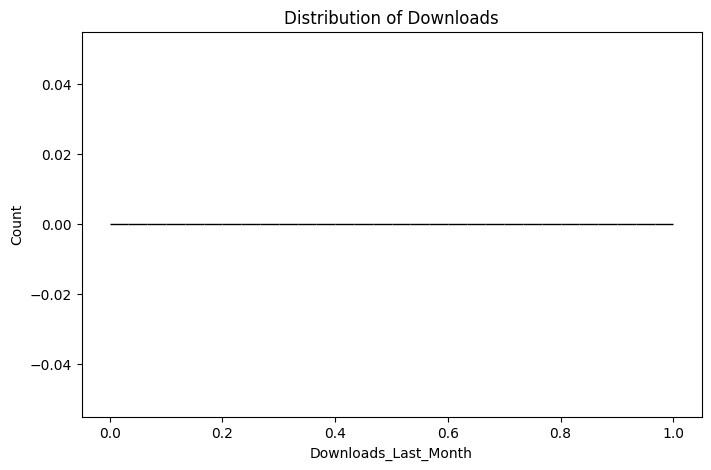

In [391]:
plt.figure(figsize=(8,5))
sns.histplot(AI["Downloads_Last_Month"].head(), bins=30,kde=True)
plt.title("Distribution of Downloads")
plt.show()

### Distribution of Likes

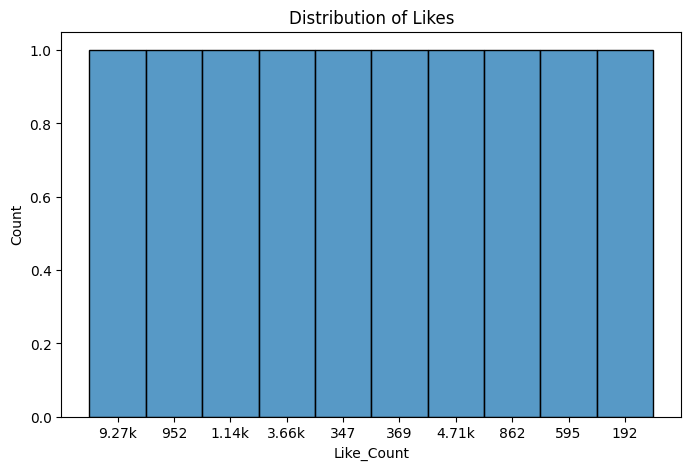

In [365]:
plt.figure(figsize=(8,5))
sns.histplot(AI["Like_Count"].head(10), bins=30)
plt.title("Distribution of Likes")
plt.show()

### Top 10 Pipeline Tags

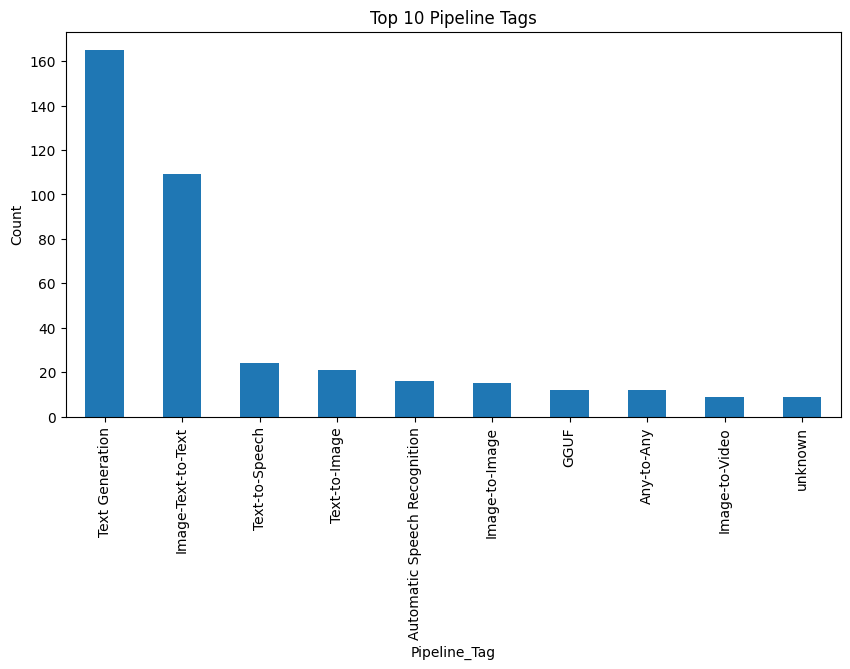

In [366]:
plt.figure(figsize=(10,5))

AI["Pipeline_Tag"].value_counts().head(10).plot(kind="bar")

plt.title("Top 10 Pipeline Tags")
plt.ylabel("Count")
plt.show()

### Top Frameworks

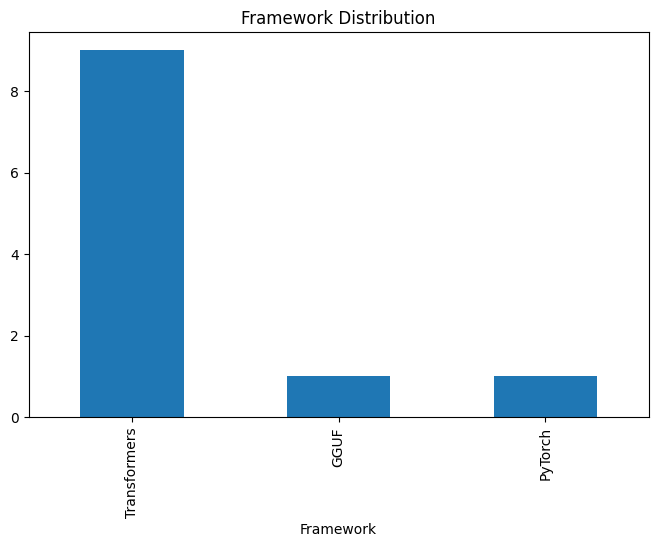

In [367]:
plt.figure(figsize=(8,5))

AI["Framework"].head(11).value_counts().plot(kind="bar")

plt.title("Framework Distribution")

plt.show()

### Language Distribution

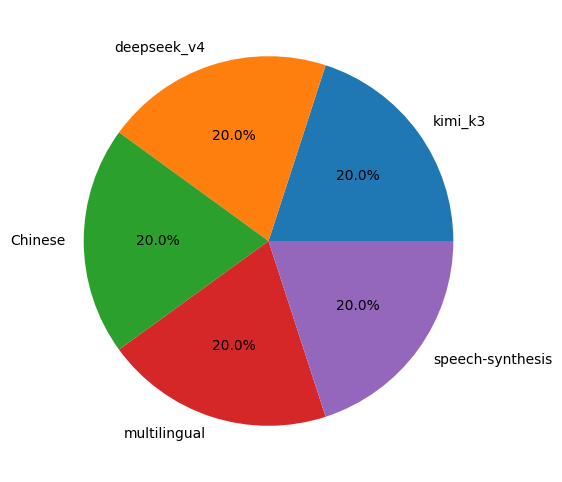

In [368]:
plt.figure(figsize=(9,6))

AI["Language"].head().value_counts().plot(kind="pie",autopct="%1.1f%%")

plt.ylabel("")

plt.show()

# Bivariate Analysis

### Downloads_Last_Month vs Like_Count

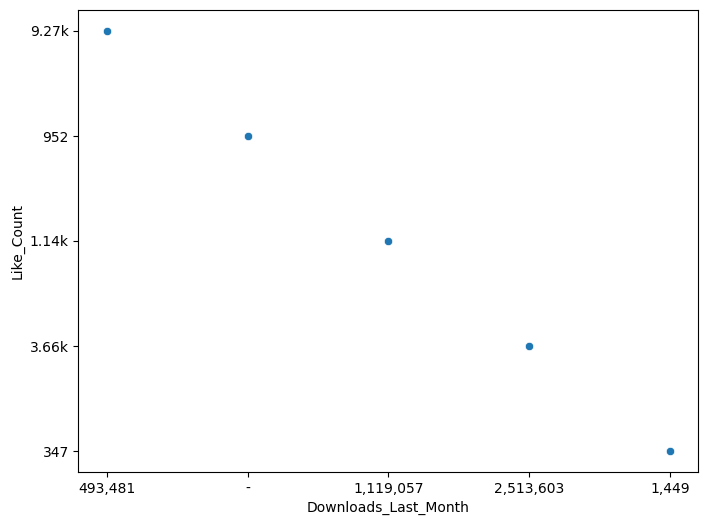

In [369]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=AI.head(),
    x="Downloads_Last_Month",
    y="Like_Count"
)

plt.show()

### Pipeline Tag vs Likes

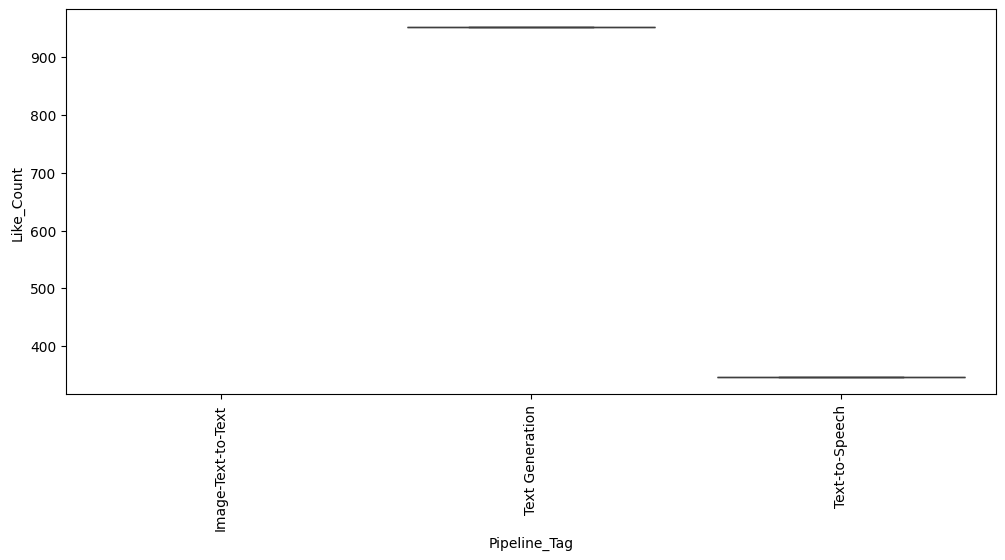

In [405]:
plt.figure(figsize=(12,5))

sns.boxplot(
    data=AI.head(),
    x="Pipeline_Tag",
    y="Like_Count"
)

plt.xticks(rotation=90)

plt.show()

### Author vs Downloads (Top 10 Authors)

In [ ]:
top = AI.groupby("Author")["Downloads_Last_Month"].sum()

top.sort_values(ascending=False).head(10).plot(kind="bar")

plt.show()

### License Distribution by Framework

In [375]:
pd.crosstab(
    AI["Framework"],
    AI["License"]
)

License,apache-2.0,appvoid-noncommercial-model-license-1.0,boson-higgs-tts-3-research-and-non-commercial-license,cc-by-4.0,cc-by-nc-4.0,cc-by-nc-nd-4.0,circlestone-labs-non-commercial-license,civitai-model-license,coqui-public-model-license,creativeml-openrail-m,...,other,qwen,researchrail,sam-license,stabilityai-ai-community,tabfm-non-commercial-v1.0,tabpfn-3-license-v1.0,tencent-hunyuan-community,unknown,upstage-solar-license
Framework,,,,,,,,,,,,,,,,,,,,,
BiRefNet,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Chatterbox,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Chinese,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Cosmos,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Diffusers,15,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,2,0
Diffusion Single File,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
English,6,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
GGUF,42,0,0,0,0,0,0,0,0,0,...,1,2,0,0,0,0,0,0,2,0
GLiNER,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0


# Multivariate Analysis

### Correlation Matrix

In [378]:
corr = AI.corr(numeric_only=True)

print(corr)
print(corr.shape)

Empty DataFrame
Columns: []
Index: []
(0, 0)


In [379]:
print(AI[[
    "Like_Count",
    "Follower_Count",
    "Downloads_Last_Month",
    "Community_Posts"
]].dtypes)

Like_Count                 str
Follower_Count          object
Downloads_Last_Month    object
Community_Posts         object
dtype: object


In [380]:
cols = [
    "Like_Count",
    "Follower_Count",
    "Downloads_Last_Month",
    "Community_Posts"
]

for col in cols:
    AI[col] = pd.to_numeric(AI[col], errors="coerce")

# Multivariate Analysis¶

### Correlation Matrix

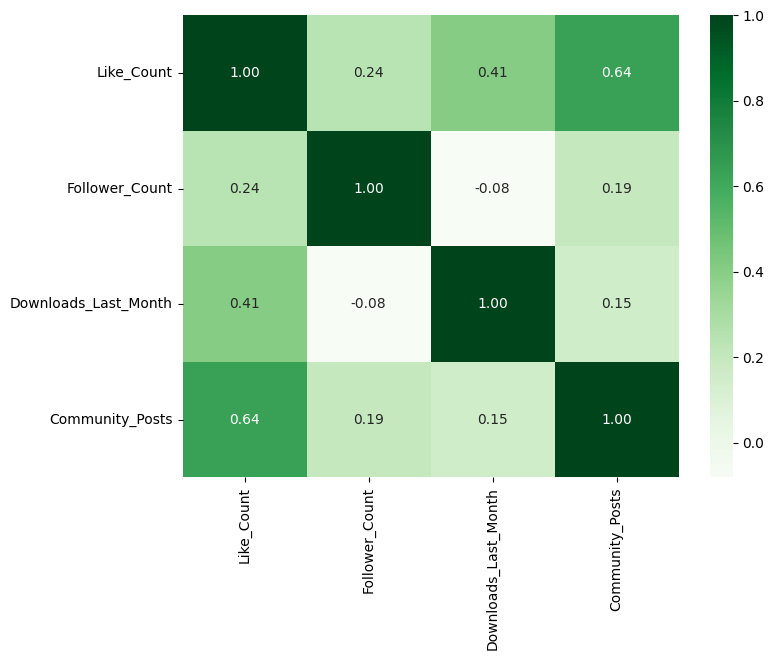

In [401]:
corr = AI.corr(numeric_only=True)

plt.figure(figsize=(8,6))

sns.heatmap(
    corr,
    annot=True,
    cmap="Greens",
    fmt=".2f"
)

plt.show()

### Pairplot

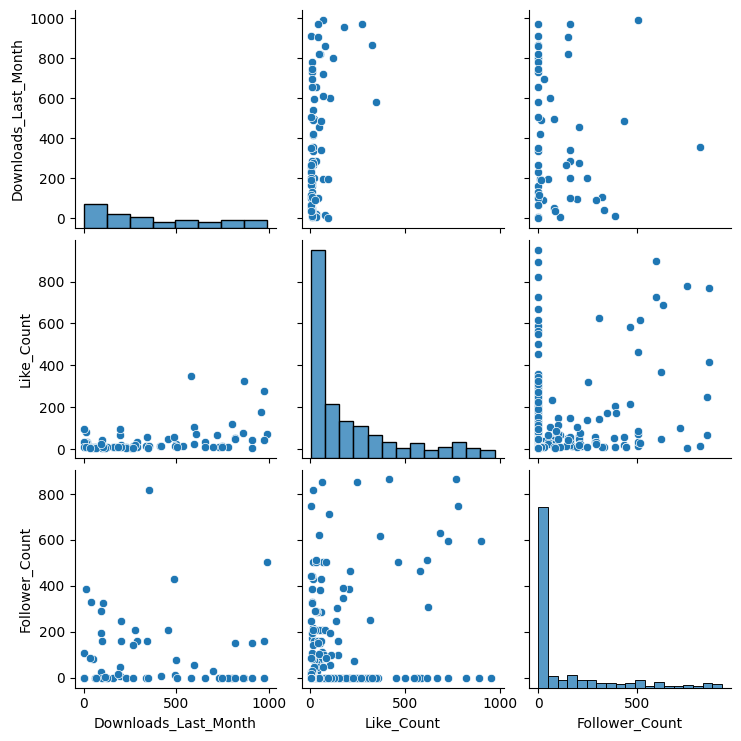

In [400]:
sns.pairplot(
    AI[[
        "Downloads_Last_Month",
        "Like_Count",
        "Follower_Count"
    ]]
)

plt.show()

# Heatmap using Crosstab

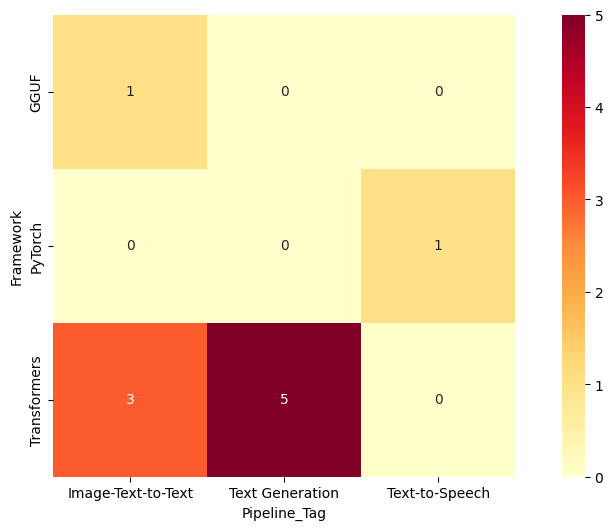

In [402]:
table = pd.crosstab(
    AI["Framework"].head(10),
    AI["Pipeline_Tag"].head(10)
)

plt.figure(figsize=(12,6))

sns.heatmap(table, cmap="YlOrRd",square=True,annot=True)

plt.show()

# HYPOTHESIS TESTING

# 1. Independent Two-Sample t-Test

# Business Question

* Do Transformer models receive more downloads than PyTorch models?

# Hypotheses
* H₀: The mean downloads of Transformer and PyTorch models are equal.
* H₁: The mean downloads are different.

In [387]:
from scipy.stats import ttest_ind

group1 = AI[AI["Framework"]=="Transformers"]["Downloads_Last_Month"]

group2 = AI[AI["Framework"]=="PyTorch"]["Downloads_Last_Month"]

t_stat, p_value = ttest_ind(group1, group2, nan_policy="omit")

print("T Statistic:", t_stat)
print("P Value:", p_value)

if p_value < 0.05:
    print("Reject H0")
else:
    print("Fail to Reject H0")

T Statistic: -0.5718572909523006
P Value: 0.5707862301188672
Fail to Reject H0


 # One-Way ANOVA

# Business Question

* Do average downloads differ across different pipeline tags?

# Hypotheses
* H₀: All pipeline tags have the same mean downloads.
* H₁: At least one pipeline tag has a different mean.

In [388]:
from scipy.stats import f_oneway

groups = [
    g["Downloads_Last_Month"].dropna()
    for _, g in AI.groupby("Pipeline_Tag")
]

f_stat, p_value = f_oneway(*groups)

print("F Statistic:", f_stat)
print("P Value:", p_value)

if p_value < 0.05:
    print("Reject H0")
else:
    print("Fail to Reject H0")

F Statistic: nan
P Value: nan
Fail to Reject H0


C:\Users\sande\AppData\Local\Temp\ipykernel_18996\3738875525.py:8: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  f_stat, p_value = f_oneway(*groups)


# Chi-Square Test

# Business Question

* Is framework associated with pipeline tag?

# Hypotheses
* H₀: Framework and Pipeline_Tag are independent.
* H₁: Framework and Pipeline_Tag are associated.

In [389]:
from scipy.stats import chi2_contingency

table = pd.crosstab(
    AI["Framework"],
    AI["Pipeline_Tag"]
)

chi2, p, dof, expected = chi2_contingency(table)

print("Chi Square:", chi2)
print("P Value:", p)

if p < 0.05:
    print("Reject H0")
else:
    print("Fail to Reject H0")

Chi Square: 6764.856945914048
P Value: 0.0
Reject H0
